In [1]:
from grokkingexperiments.config import load_config, print_config
from grokkingexperiments.model import GrokkingModel
from grokkingexperiments.tasks import select_task
from grokkingexperiments.train import train_model

import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

In [2]:
config = load_config("../../../../config.toml")
print_config(config)

Config
  model
    | actv_func       relu
    | embed_dim       128
    | hidden_dim      256
  train
    | epochs          15000
  task
    | type            group
    | name            Zn
    | n               64
    | split           0.4
  settings
    | seed            1337
    | print_progress  True


Epoch  0      | Loss 4.191  | Test loss 4.196  | Train accuracy 0.015  | Test accuracy 0.012 
Epoch  100    | Loss 0.438  | Test loss 8.821  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  200    | Loss 0.067  | Test loss 10.138 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  300    | Loss 0.046  | Test loss 9.911  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  400    | Loss 0.037  | Test loss 9.633  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  500    | Loss 0.031  | Test loss 9.376  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  600    | Loss 0.027  | Test loss 9.133  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  700    | Loss 0.024  | Test loss 8.890  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  800    | Loss 0.021  | Test loss 8.632  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  900    | Loss 0.019  | Test loss 8.347  | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  1000   | Loss 0.017  | Test loss 8.035  | Train accur

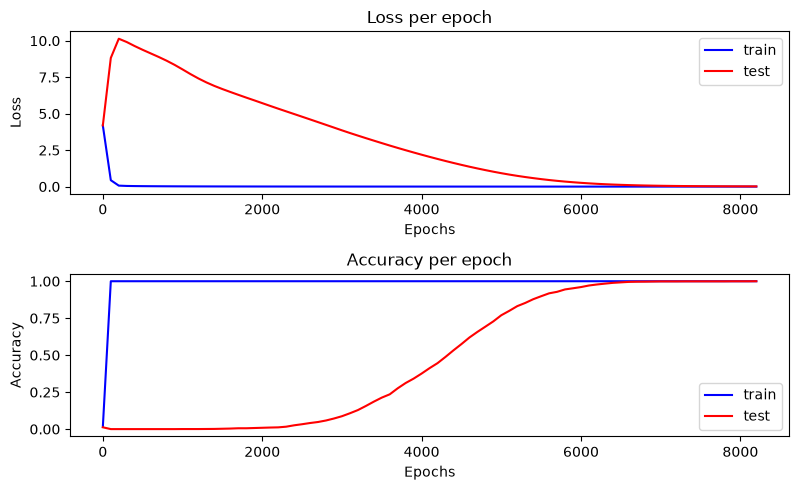

In [3]:
# Create Model
model = GrokkingModel(config).to(device)

# Select the task and generate data
task  = select_task(config)
x_train, y_train, x_test, y_test = task.generate_train_test_data()

# Move data to the same device as the model
x_train = x_train.to(device)
y_train = y_train.to(device)
x_test = x_test.to(device)
y_test = y_test.to(device)

# Train the model
train_model(config, model, x_train, y_train, x_test, y_test)

# plot results
model.plot_metrics()